# HD 206893 with amigo 0.1 and the 0.0.10 calibration
HD 206893 and its calibrator HD 205827 (JWST GO 1843, 2022-10-26, one exposure each in F380M, F430M and F480M), from calslopes to companion fits, with `amigo-pipeline` and `virgil`. The instrument is the paper's `calibration.npy` (amigo 0.0.10). HD 206893 has two companions: the brown dwarf B (~200 mas) and the planet c (~100 mas).

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as np
import numpy as onp

import amigo_pipeline

from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt

load_dict = lambda x: np.load(x, allow_pickle=True).item()

# amigo-pipeline

The first stage of this notebook is to put the calslope data through the amigo-pipeline.

## Loading Data

In [2]:
import os
from amigo.files import get_files

home_path = "/media/morgana1/snert/max/data/"
data_dir = os.path.join(home_path, "JWST/1843/calslope_amigo-0.1/")
output_path = os.path.join(home_path, "pipeline_outputs/hd206893_tauron")

# loading in the calslope files
files = get_files(
    data_dir,
    "calslope",
    EXP_TYPE="NIS_AMI",
    TARGPROP=["HD-206893", "HD-205827"],
)
files = sorted(files, key=lambda f: f.filename())

## Instrument calibration
The paper's `calibration.npy`, converted by `convert_calibration_v2.py` with per-visit piston/tip/tilt shared across
filters (`ptt` sharing `program`, which amigo `be7cee0` and later require).

In [3]:
from amigo_pipeline.calibration import load_calibration

# path to saved instrumental state from base model calibration
calibration_path = os.path.join(
    home_path, "amigo_files/v_0.0.11/v2_from_calibration_npy_ptt_program"
)

# dict of model-construction inputs: detector, ramp_model, read, vis_model
# (AmigoModel), opd_calibration (AMIOptics) and defocus (per-filter values)
state = load_calibration(Path(calibration_path))

## Exposures
Exposures of one star, filter and roll share their visibilities.

In [4]:
from amigo.model_fits import SplineVisFit
from amigo_pipeline.dataset import visibility_key

roll_tolerance = 1e-3  # degrees; recorded in model_recipe below
groups = {}
exposures = []

for f in files:
    role = "calibrator" if f[0].header["IS_PSF"] else "science"
    vis_key = visibility_key(f[0].header, role, groups, roll_tolerance)
    exposures.append(SplineVisFit(f, vis_key=vis_key))

## Building the model

In [5]:
from amigo_pipeline.dataset import DEFAULT_OPTICS
from amigo.core_models import AmigoModel
from amigo.optical_models import AMIOptics

filters = sorted({exp.filter for exp in exposures})

model = AmigoModel(
    exposures,
    optics=AMIOptics(
        opd_calibration=state["opd_calibration"],
        filters=filters,
        **DEFAULT_OPTICS,
    ),
    detector=state["detector"],
    ramp_model=state["ramp_model"],
    read=state["read"],
    vis_model=state["vis_model"],
)

# setting model defocus
for f in filters:
    model = model.set(f"params.defocus.{f}", np.asarray(state["defocus"][f]))

## Pairs
Each HD 206893 exposure is calibrated by the HD 205827 exposure in its filter.

In [6]:
pairs = []
for f in filters:
    calibrators = sorted(
        exp.key for exp in exposures if exp.filter == f and exp.calibrator
    )
    visits = {}
    for exp in exposures:
        if exp.filter == f and not exp.calibrator:
            visits.setdefault(exp.vis_key, []).append(exp)
    for visit in visits.values():
        pairs.append(
            {
                "name": f"{visit[0].star}_{f}_obs{visit[0].observation}",
                "science": [exp.key for exp in visit],
                "calibrator": calibrators,
                "reference": calibrators[0],
            }
        )

## Cache provenance
The files the model is built from, and how it is built from them.

In [7]:
from amigo_pipeline.storage import file_hash

# The pipeline keys its cached initial state on these file hashes and this recipe instead
# of the model's raw arrays, so GPU roundoff when rebuilding the model can't invalidate the
# cache: on resume it restores the saved arrays. The recipe must describe everything above
# that decides how the model is built, so update it (or bump "builder") when that changes.
source_files = {
    str(path): file_hash(path)
    for path in [
        *Path(calibration_path).iterdir(),
        *(Path(f.filename()) for f in files),
    ]
    if path.is_file()
}
model_recipe = {
    "builder": "HD206893_pipeline_v0.1",
    "exposures": {"roll_tolerance": roll_tolerance},
    "optics": {**DEFAULT_OPTICS, "filters": filters},
    "vis_model": "PlaceholderVisModel",
}

## Run the pipeline
`run()` resumes: stages already completed in `output` with the same inputs are loaded, not refitted. With
`strict=False`, a completed stage whose inputs differ is reused with a warning instead of raising. A new folder runs
everything (about 1.6 h and 17 GB on an A100).

In [8]:
pipeline = amigo_pipeline.Pipeline(
    exposures,
    model,
    pairs,
    output=output_path,
    roll_tolerance=roll_tolerance,
    source_files=source_files,
    model_recipe=model_recipe,
)
discos, cross = pipeline.run(
    strict=False,
)

inputs: cached inputs differ; reusing the cached stage (strict=False)
instrument: cached inputs differ; reusing the cached stage (strict=False)
reference: cached inputs differ; reusing the cached stage (strict=False)
basis/F380M: cached inputs differ; reusing the cached stage (strict=False)
basis/F430M: cached inputs differ; reusing the cached stage (strict=False)
basis/F480M: cached inputs differ; reusing the cached stage (strict=False)
visibility/01843_001_01_05_1: cached inputs differ; reusing the cached stage (strict=False)
endpoints/01843_001_01_05_1: cached inputs differ; reusing the cached stage (strict=False)
visibility/01843_001_01_06_1: cached inputs differ; reusing the cached stage (strict=False)
endpoints/01843_001_01_06_1: cached inputs differ; reusing the cached stage (strict=False)
visibility/01843_001_01_07_1: cached inputs differ; reusing the cached stage (strict=False)
endpoints/01843_001_01_07_1: cached inputs differ; reusing the cached stage (strict=False)
visibilit

The pipeline draws its own figures: the calibrator's instrument fit, HD 206893 fitted as a point source (the
companions show in the residuals), and the DISCOs.

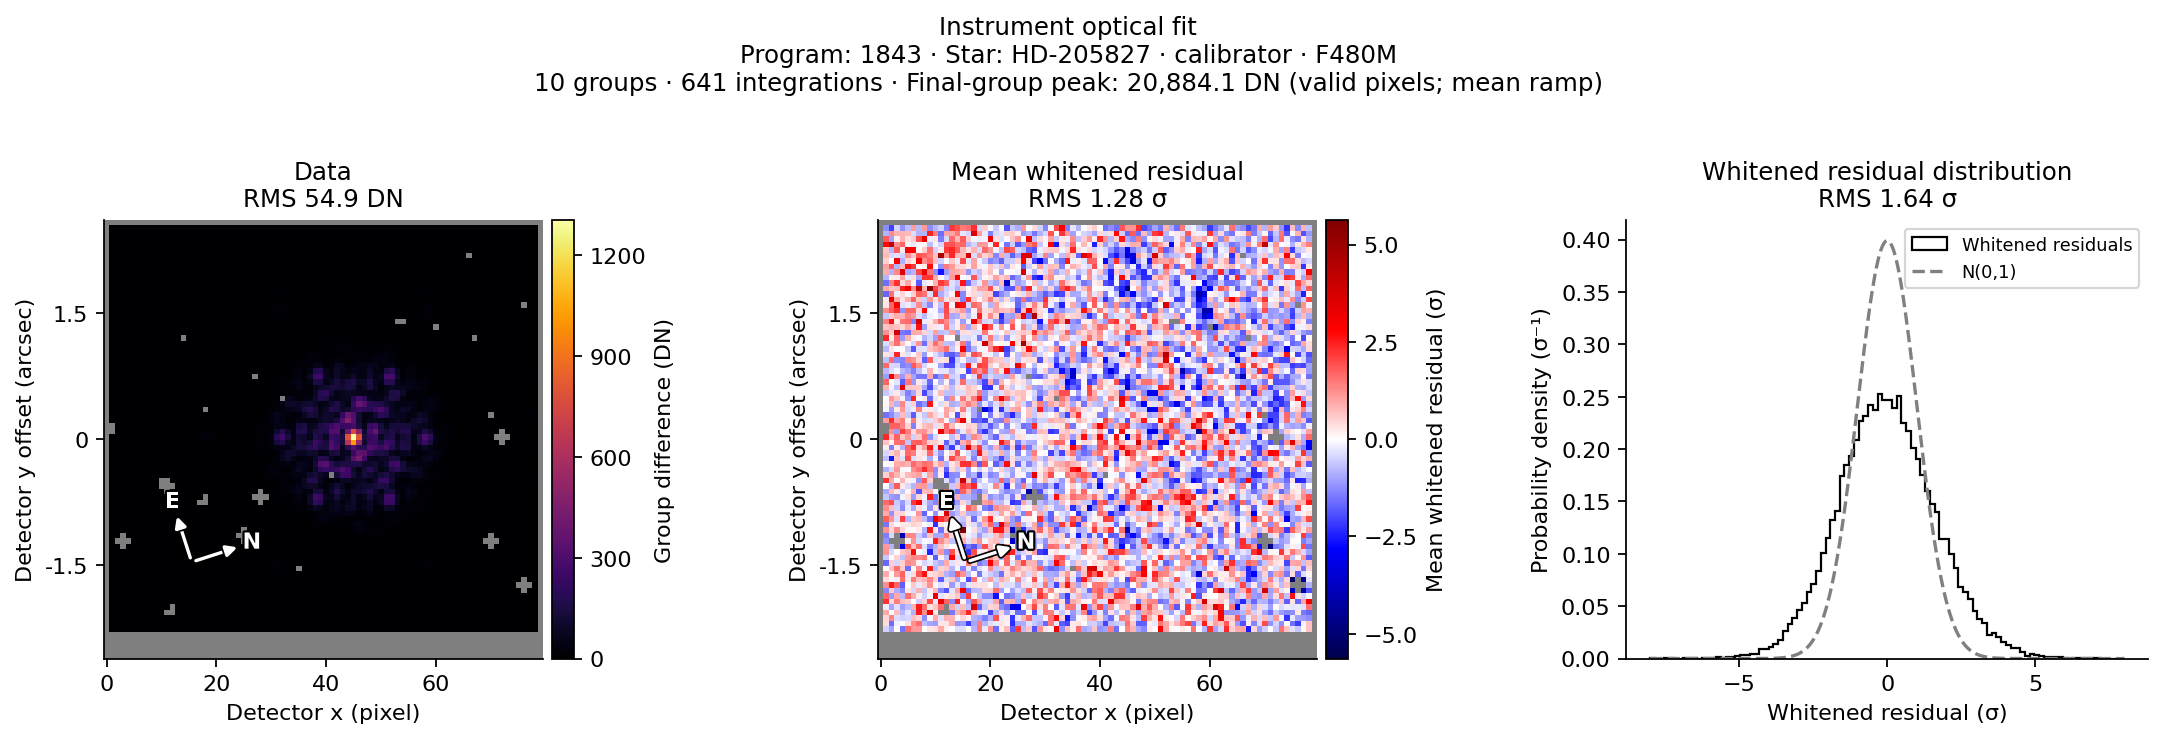

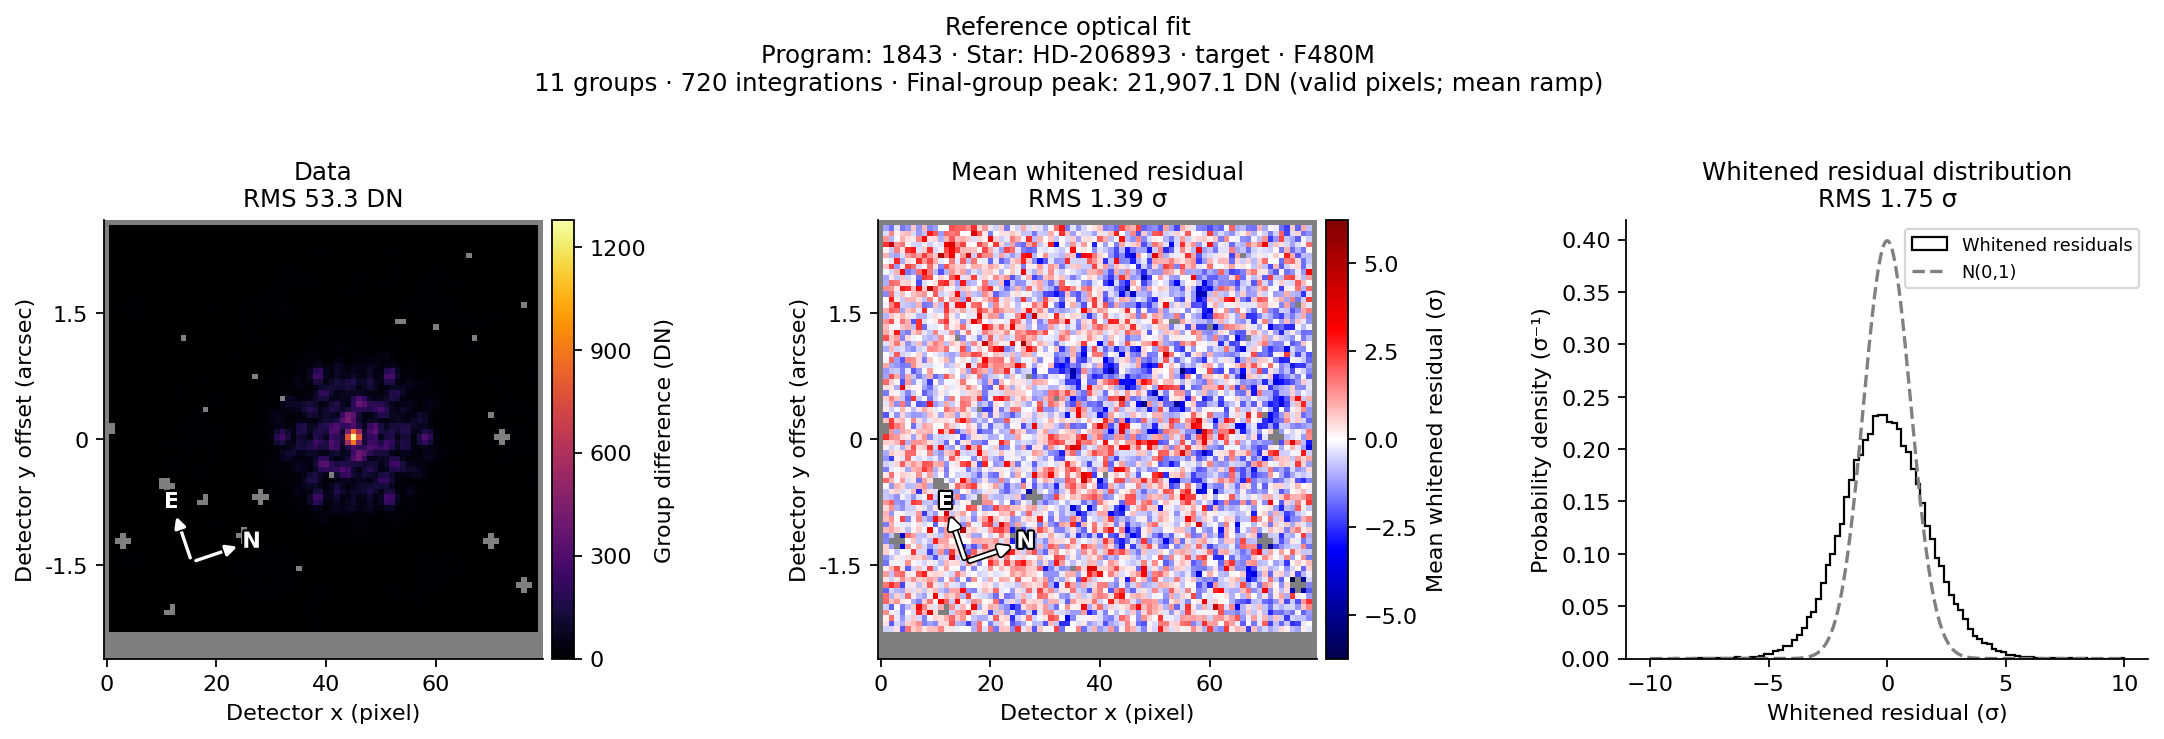

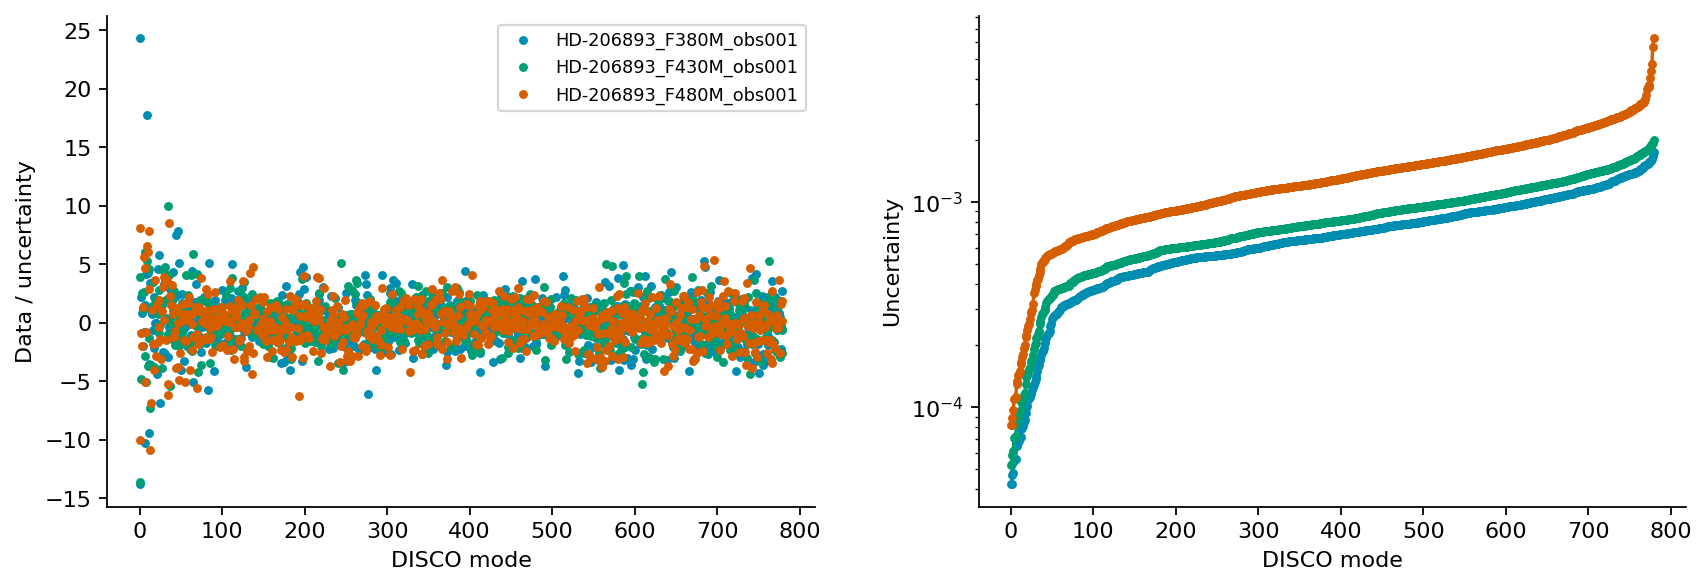

In [9]:
for figure in [
    "instrument/pixels_0.png",
    "reference/pixels_0.png",
    "products/discos.png",
]:
    display(Image(filename=str(Path(output_path) / figure)))

## How the fits went
Every pipeline fit, one row per exposure. `residual_rms_sigma` is the RMS of the whitened detector residuals, so 1 means
the fit reaches the noise and larger values are model error (or underestimated noise). `gradient` is the largest
normalised gradient at the end of the fit (the acceptance threshold is 1e-6).

In [10]:
import pipeline_plots

pipeline_plots.fit_summary(output_path).round({"residual_rms_sigma": 2, "minutes": 1})

filter        role  residual_rms_sigma  \
stage      exposure                                                   
instrument 01843_002_01_04_1  F480M  calibrator                1.64   
           01843_002_01_05_1  F380M  calibrator                5.41   
           01843_002_01_06_1  F430M  calibrator                2.80   
reference  01843_001_01_05_1  F480M      target                1.75   
           01843_001_01_06_1  F380M      target                5.21   
           01843_001_01_07_1  F430M      target                2.86   
visibility 01843_001_01_05_1  F480M      target                1.55   
           01843_001_01_06_1  F380M      target                4.24   
           01843_001_01_07_1  F430M      target                2.40   
           01843_002_01_04_1  F480M  calibrator                1.46   
           01843_002_01_05_1  F380M  calibrator                4.40   
           01843_002_01_06_1  F430M  calibrator                2.30   

                                       status      gradient  minutes  
stage      exposure                                                   
instrument 01843_002_01_04_1  gradient_target  1.206682e-07      5.7  
           01843_002_01_05_1  gradient_target  1.206682e-07      5.7  
           01843_002_01_06_1  gradient_target  1.206682e-07      5.7  
reference  01843_001_01_05_1  gradient_target  1.258166e-07      3.2  
           01843_001_01_06_1  gradient_target  1.258166e-07      3.2  
           01843_001_01_07_1  gradient_target  1.258166e-07      3.2  
visibility 01843_001_01_05_1  gradient_target  3.844683e-08      5.0  
           01843_001_01_06_1  gradient_target  8.886113e-08      4.6  
           01843_001_01_07_1  gradient_target  2.603484e-08      4.8  
           01843_002_01_04_1  gradient_target  1.432082e-08      5.0  
           01843_002_01_05_1  gradient_target  3.434267e-07      4.5  
           01843_002_01_06_1  gradient_target  4.187892e-08      4.8

Whitened detector residuals for every exposure, from the point-source fit (calibrators: instrument stage; HD 206893:
reference stage) and from the visibility fit. Structure that survives the visibility fit is not explained by the
visibility basis.

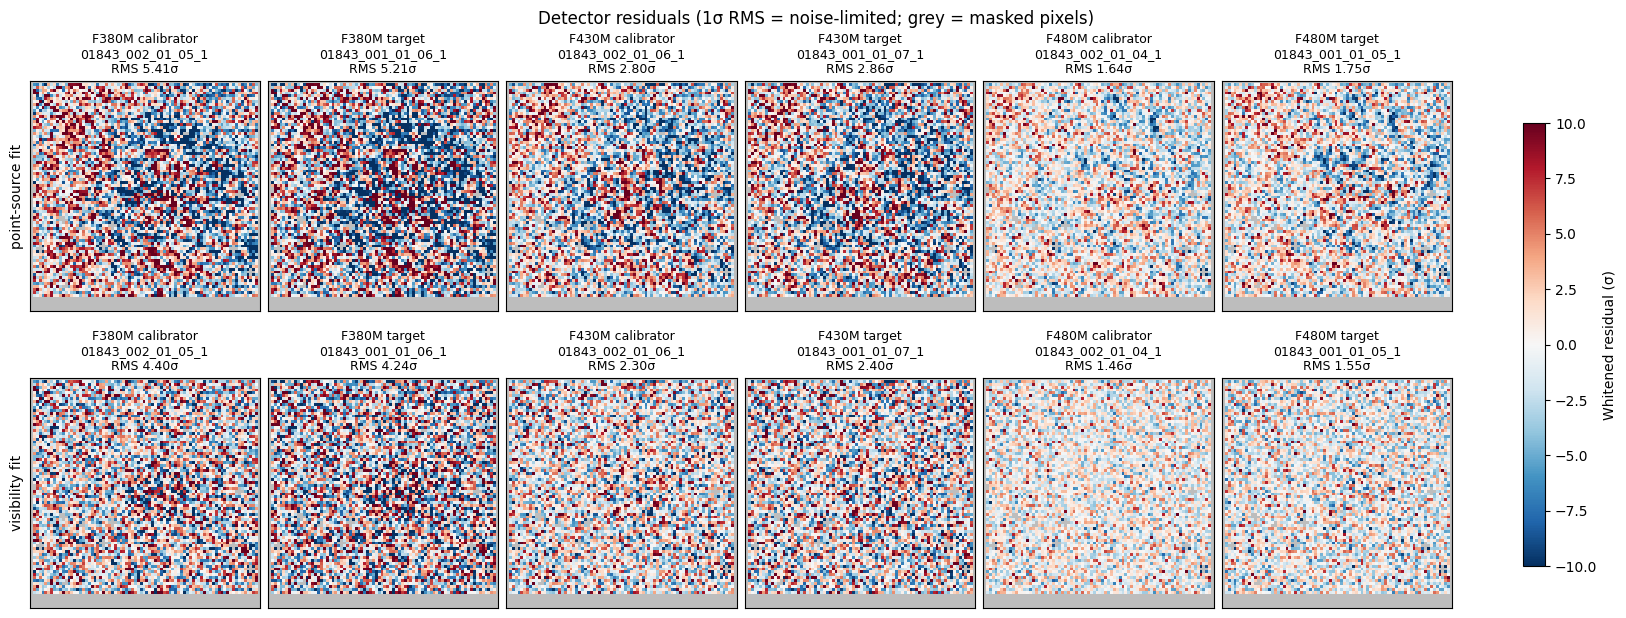

In [11]:
pipeline_plots.residual_grid(output_path)
plt.show()

## Visibilities in the uv plane
Each fit's visibility coefficients times the basis modes give the log-visibility it fitted on the uv grid, relative to
the optical model. Science and calibrator share a colour scale, so the instrument signature they have in common is
visible; the calibrated column (science minus calibrator) is what goes into the DISCOs. Axes are in the instrument
frame, not on the sky.

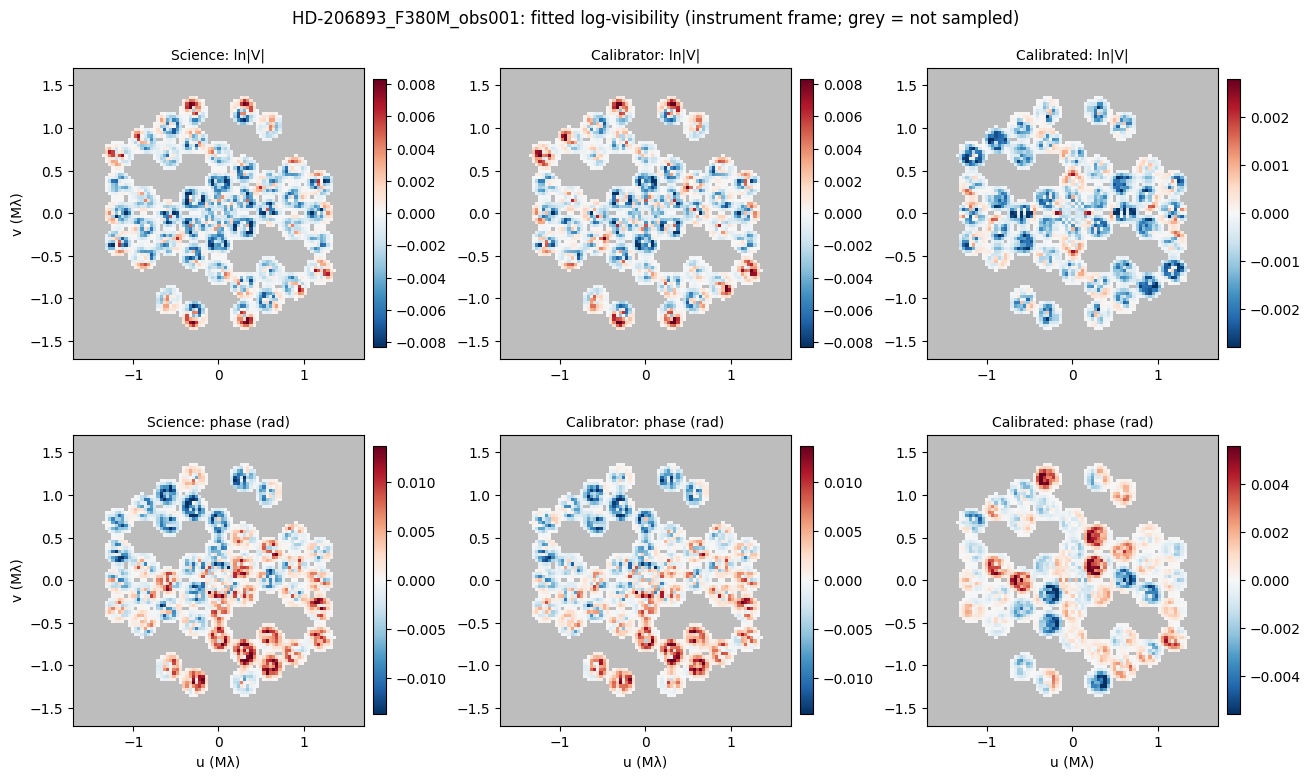

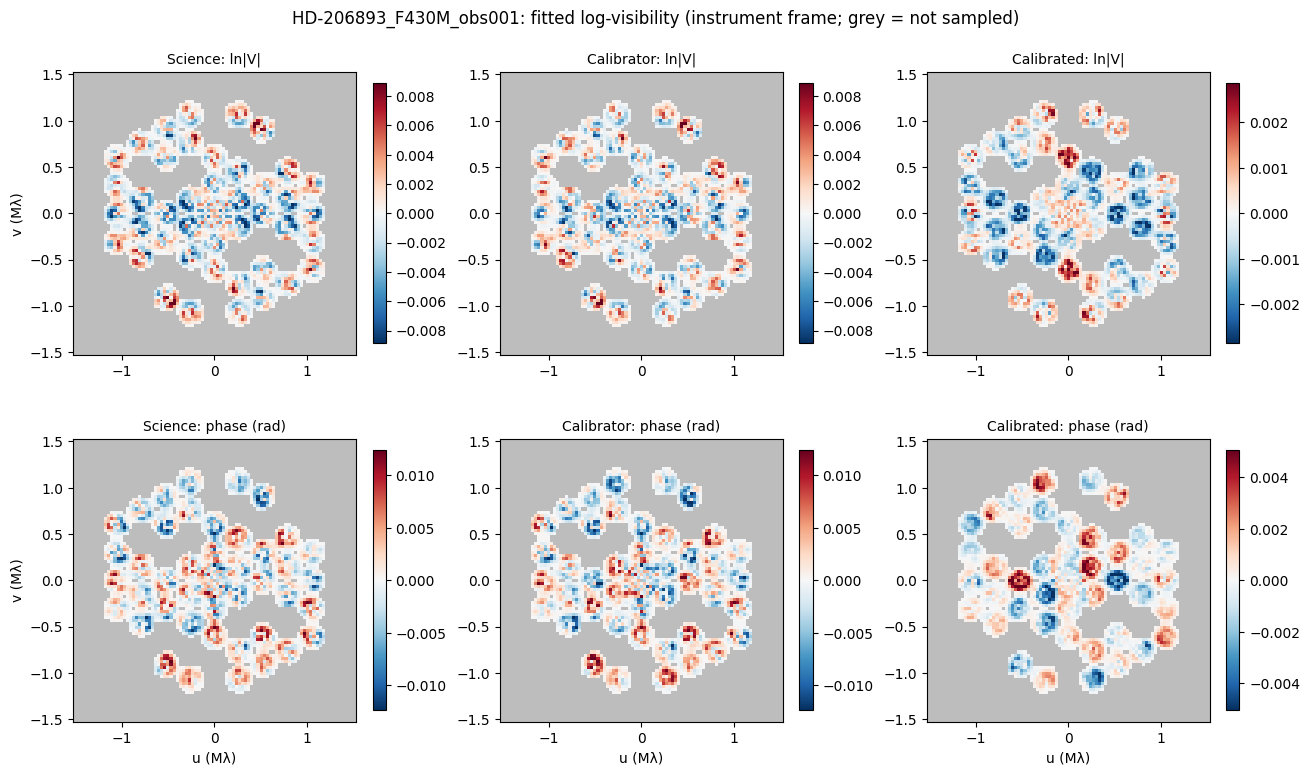

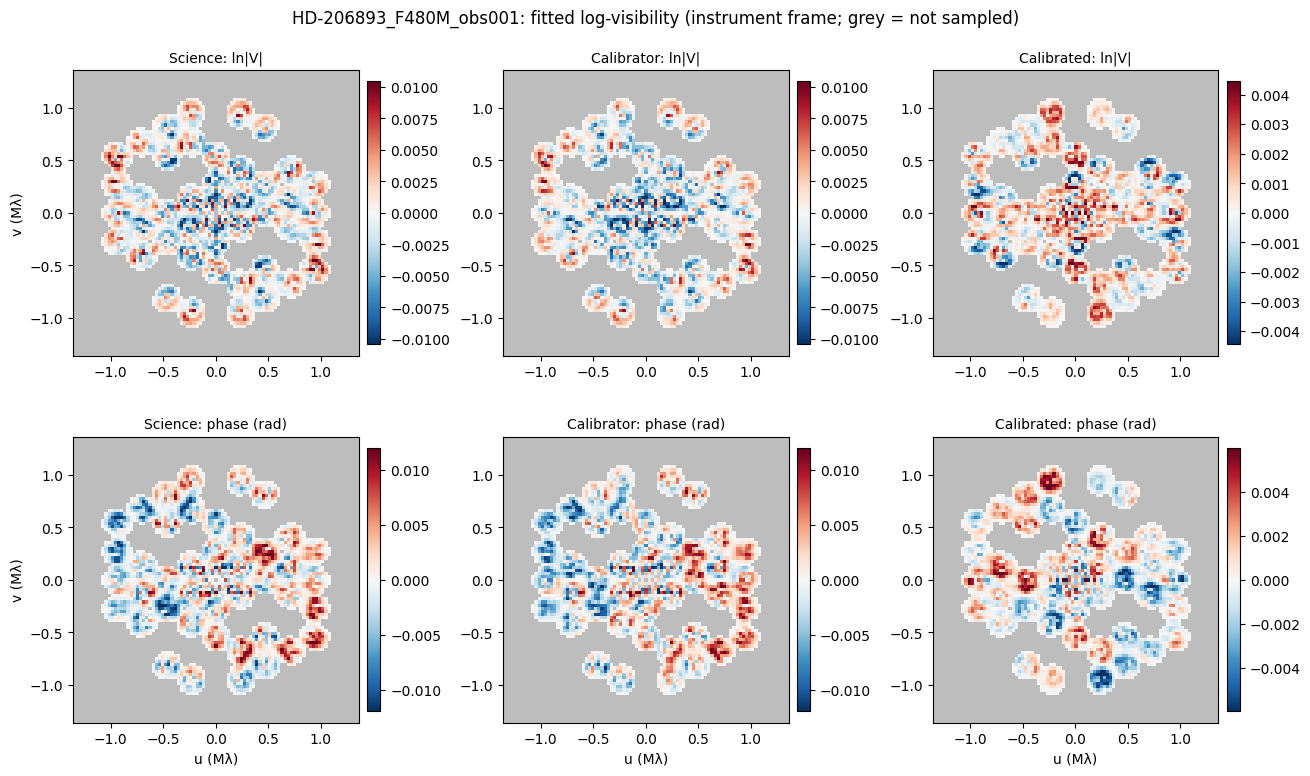

In [12]:
for name, disco in discos.items():
    pipeline_plots.uv_visibilities(output_path, name, disco)
    plt.show()

# virgil

## B: one companion
Virgil's binary pipeline on each filter's DISCOs. It fits a single companion, so it finds B, the brighter one.

The fit's reduced χ² is 3-5 with the errors as quoted, so the quoted errors are too small; the `x √χ²` columns scale
them up to make χ²/dof = 1 (a rough correction: it assumes the excess scatter is white).

PA here is east of north (Virgil's convention). The AMIGO paper's tables give 90° − PA (the angle from east
towards north): its AB Dor C 169.48° is 280.52° east of north, and our pipeline gives 280.55°. GRAVITY puts B at
PA 33° in 2019-07 and 6° in 2021-08 (Hinkley et al. 2023, Table 2), moving about −13° a year, so about 350° at
this epoch.

In [13]:
from virgil.grid_fit import likelihood_grid
from virgil.likelihood import model_loglike, whitened_residuals
from virgil.models import PointSource, System
from virgil.pipeline import BinaryPipeline

from amigo.discos import to_virgil

import pandas as pd

/home/max/conda/miniconda3/envs/0.1/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
results = {
    name: BinaryPipeline(
        to_virgil(disco),
        output=Path(output_path) / "binary" / name,
        max_sep_mas=600.0,
        n_flux=80,
    ).run()
    for name, disco in discos.items()
}

rows = {}
for name, res in results.items():
    c, s = res.summary["companion"], res.summary["chi2"]
    k = onp.sqrt(s["companion_reduced"])
    rows[name.split("_")[1]] = {
        "sep_mas": c["sep_mas"],
        "sep_err": c["sep_err_mas"],
        "sep_err_x_sqrt_chi2": k * c["sep_err_mas"],
        "pa_deg": c["pa_deg"],
        "pa_err": c["pa_err_deg"],
        "pa_err_x_sqrt_chi2": k * c["pa_err_deg"],
        "delta_mag": c["delta_mag"],
        "chi2_reduced": s["companion_reduced"],
        "detection_sigma": res.summary["search"]["local_nsigma"],
    }
B_table = pd.DataFrame(rows).T
B_table.round(2)

,sep_mas,sep_err,sep_err_x_sqrt_chi2,pa_deg,pa_err,pa_err_x_sqrt_chi2,delta_mag,chi2_reduced,detection_sigma
F380M,200.72,3.12,6.82,347.40,1.23,2.69,8.48,4.79,14.77
F430M,199.36,4.12,6.89,352.16,1.25,2.09,7.95,2.79,19.35
F480M,172.17,7.56,13.58,346.53,1.50,2.69,7.74,3.23,17.39


The AMIGO paper's B (Table 6, per-filter fits), with its PA converted to east of north:

In [15]:
paper_B = pd.DataFrame(
    {
        "F380M": (199.3, 101.9, 8.33),
        "F430M": (192.1, 99.4, 7.96),
        "F480M": (199.4, 104.0, 7.47),
    },
    index=["sep_mas", "paper_pa", "delta_mag"],
).T
paper_B["pa_deg (east of north)"] = (90 - paper_B["paper_pa"]) % 360
paper_B.join(B_table[["sep_mas", "pa_deg", "delta_mag"]], rsuffix=" (this run)").round(
    2
)

,sep_mas,paper_pa,delta_mag,pa_deg (east of north),sep_mas (this run),pa_deg,delta_mag (this run)
F380M,199.3,101.9,8.33,348.1,200.72,347.40,8.48
F430M,192.1,99.4,7.96,350.6,199.36,352.16,7.95
F480M,199.4,104.0,7.47,346.0,172.17,346.53,7.74


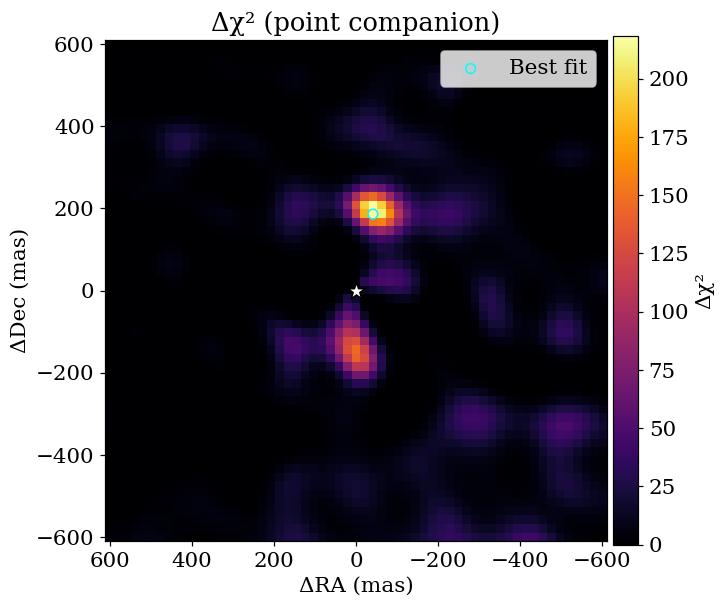

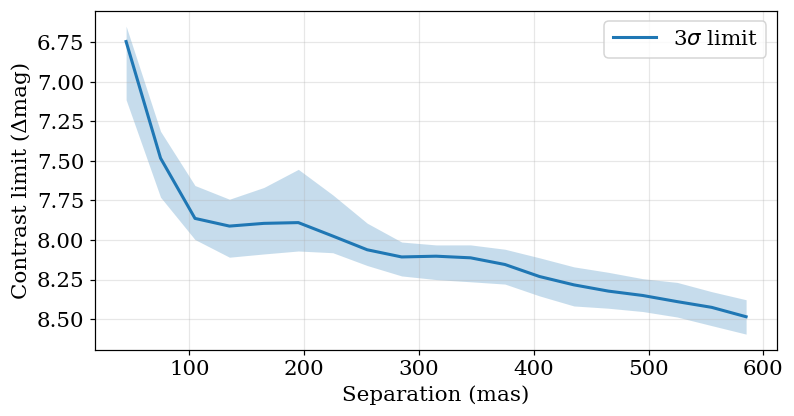

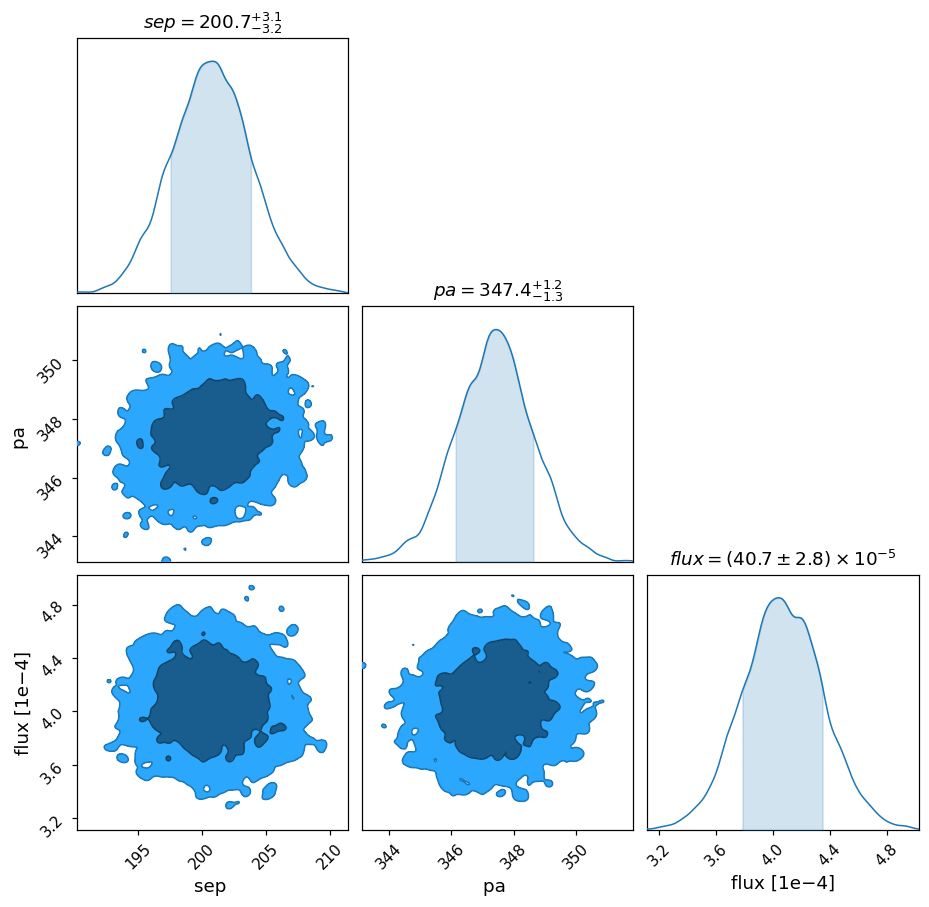

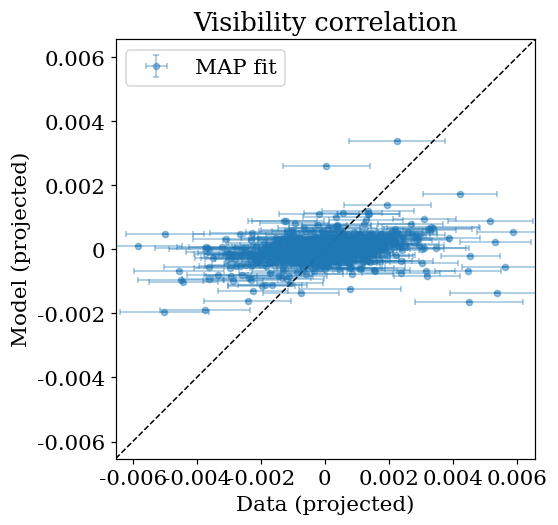

In [16]:
plots = Path(output_path) / "binary" / next(iter(results)) / "plots"
for plot in [
    "search_delta_chi2",
    "limits_contrast_curve",
    "posterior_corner",
    "fit_correlation",
]:
    display(Image(filename=str(plots / f"{plot}.png")))

Calibrated visibilities against the best-fit binary, drawn in the uv plane in units of σ. Both are projected the same
way as the DISCOs, so this is the comparison Virgil fits, laid out in uv. Neighbouring uv points are correlated, so the
residual RMS is a guide rather than a χ²; the reduced χ² is in the table above.

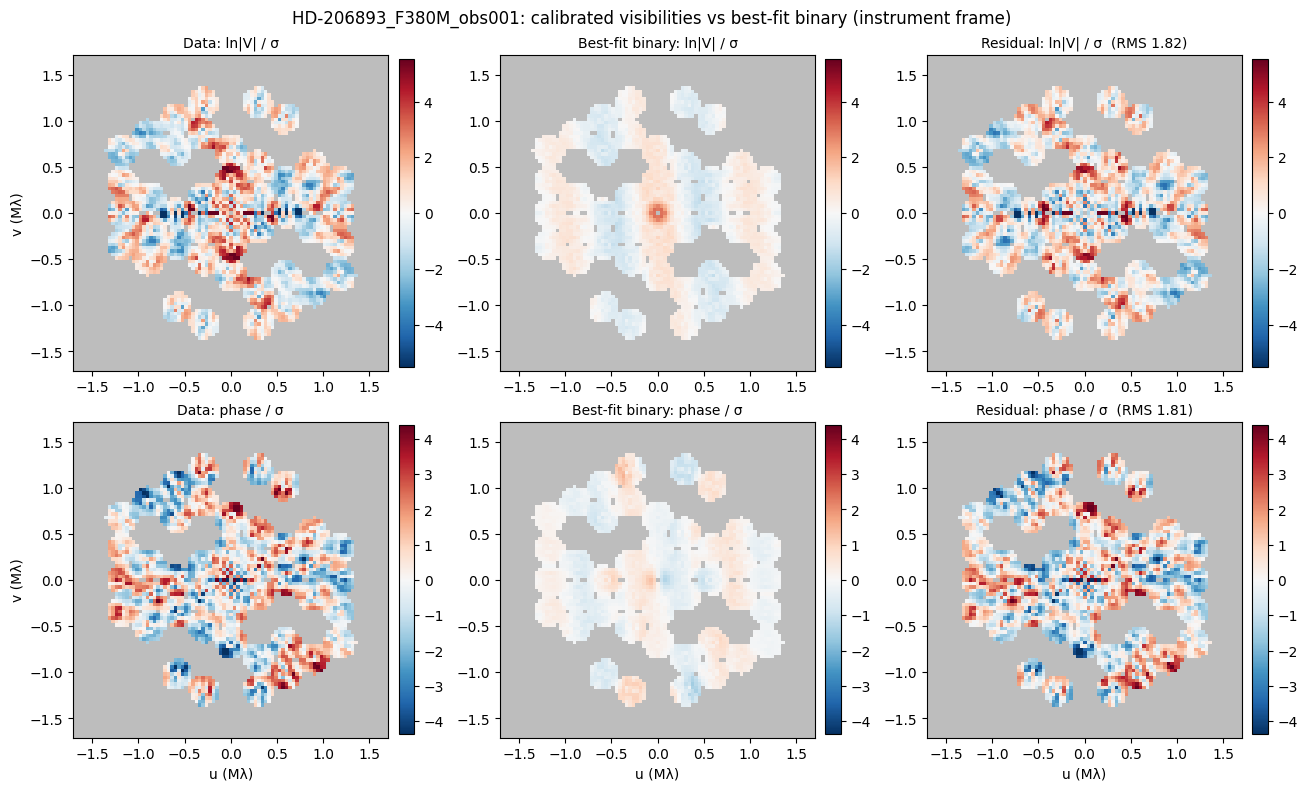

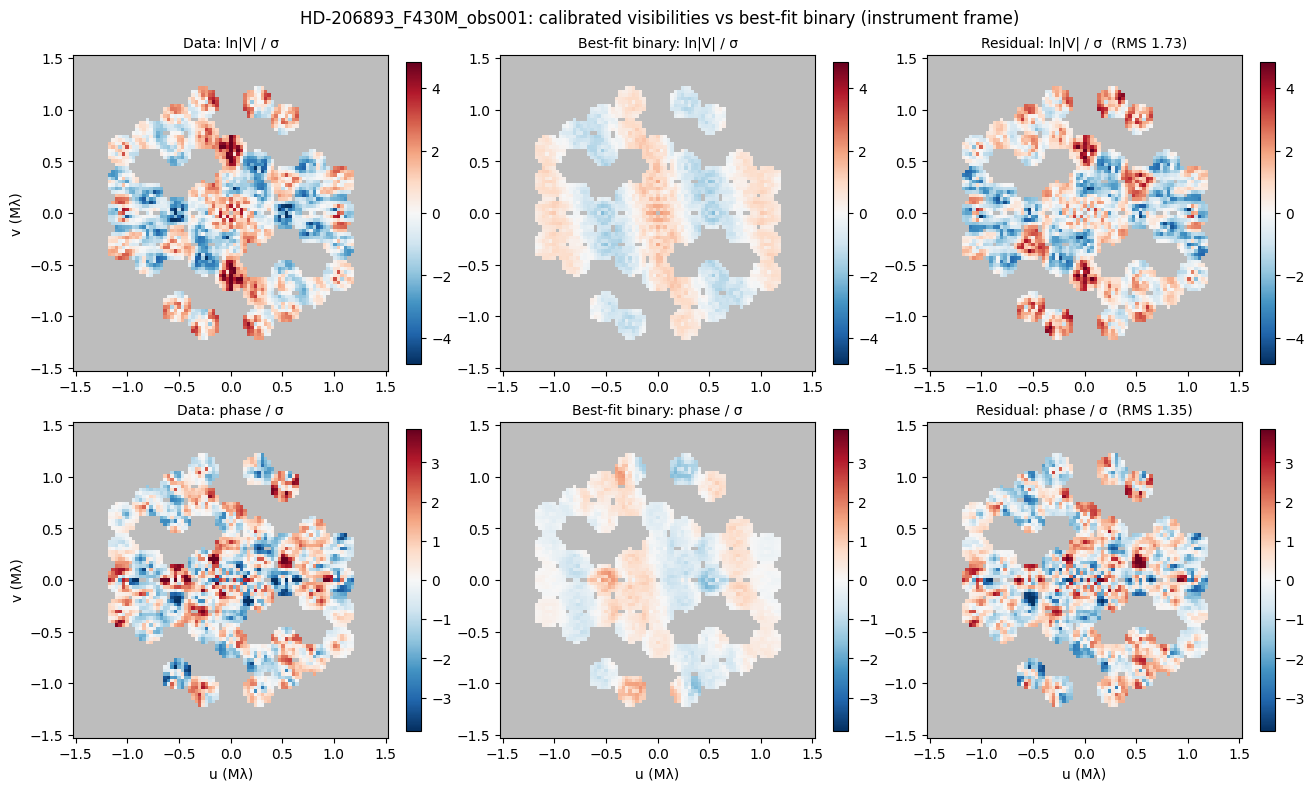

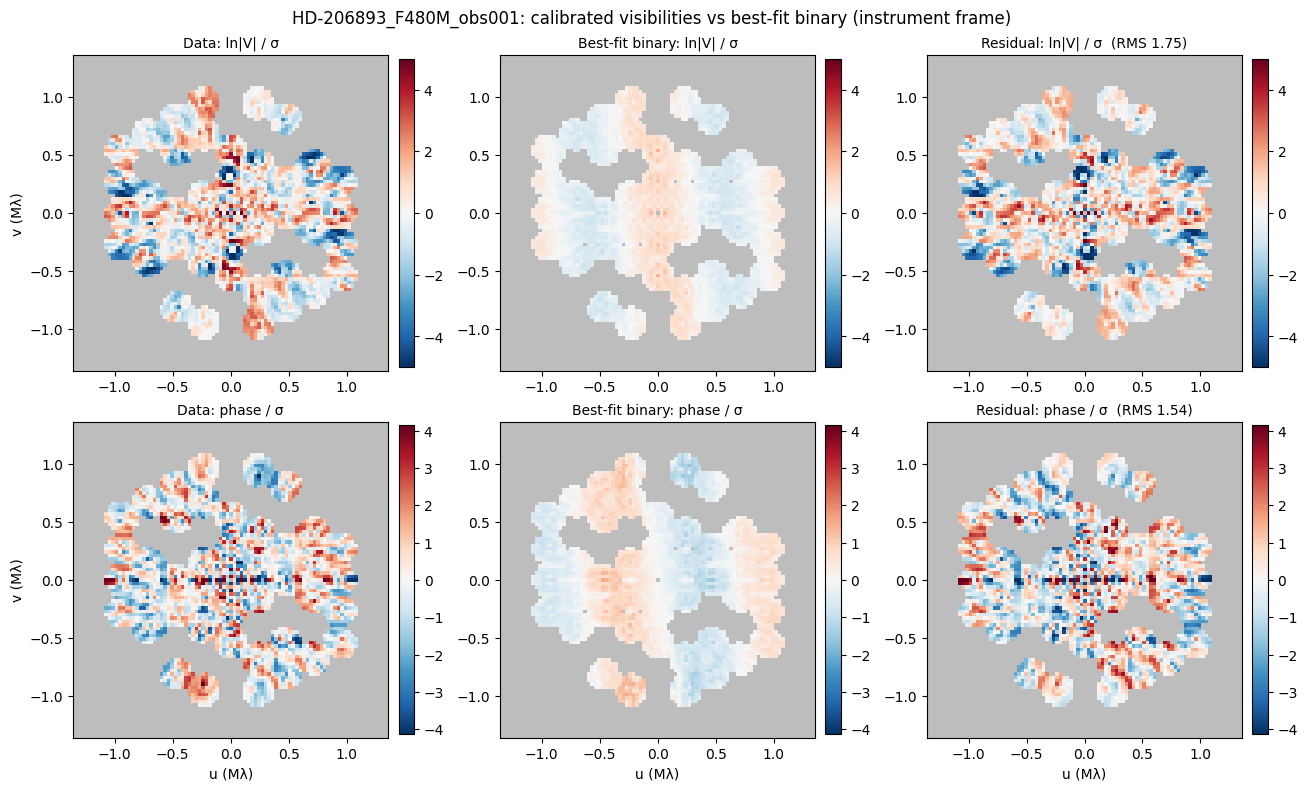

In [17]:
for name, disco in discos.items():
    c = results[name].summary["companion"]
    binary = System(
        star=PointSource(),
        B=PointSource(flux=c["flux"], dra=c["dra_mas"], ddec=c["ddec_mas"]),
    )
    pipeline_plots.uv_model_comparison(
        output_path, name, disco, binary, label="best-fit binary"
    )
    plt.show()

## c: a second companion with B in the model
B held at its fit above, plus a second point source on a grid of positions and fluxes. The map is the
improvement in χ² over B alone, at the best flux in each position. The circle marks the paper's c (Table 7, per
filter, PA converted); the cross marks B.

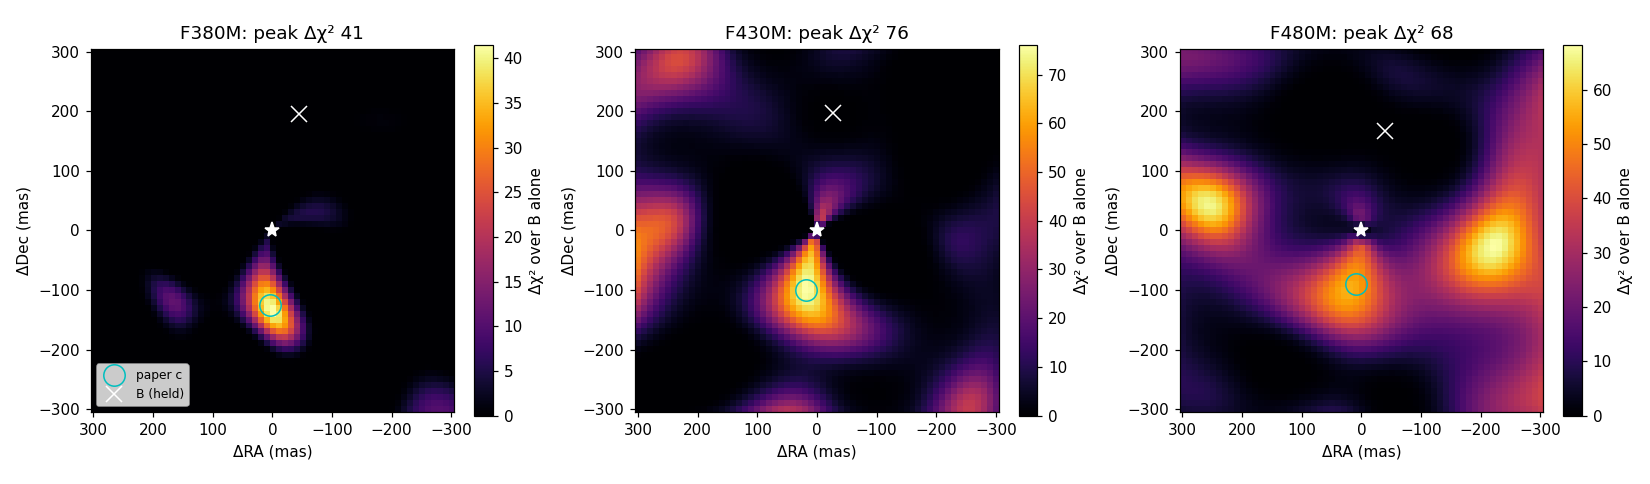

In [18]:
axis = onp.arange(-300.0, 301.0, 10.0)  # mas
fluxes = onp.geomspace(1e-5, 3e-3, 30)  # c / A
paper_c = {
    "F380M": (125, -88.0),
    "F430M": (102, -79.6),
    "F480M": (91, -83.8),
}  # sep (mas), paper PA (deg)


def offsets(sep, pa_deg):
    th = onp.radians(pa_deg)
    return sep * onp.sin(th), sep * onp.cos(th)


searches = {}
for name, disco in discos.items():
    data = to_virgil(disco)
    b = results[name].summary["companion"]
    dra, ddec = offsets(b["sep_mas"], b["pa_deg"])
    B = PointSource(flux=b["flux"], dra=dra, ddec=ddec)
    ll_B = float(model_loglike(System(star=PointSource(), B=B), data))
    scene = System(star=PointSource(), B=B, c=PointSource(flux=1e-4, dra=0.0, ddec=0.0))
    ll = onp.asarray(
        likelihood_grid(
            scene, data=data, grid={"c.dra": axis, "c.ddec": axis, "c.flux": fluxes}
        )
    )
    dchi2 = 2 * (ll.max(-1) - ll_B)  # (dra, ddec)
    best_flux = fluxes[ll.argmax(-1)]
    # two starting points for the joint fit: the map's peak, and its peak inside 150 mas (where GRAVITY's orbit puts c)
    starts = []
    for inside in (
        onp.ones_like(dchi2, bool),
        onp.hypot(*onp.meshgrid(axis, axis, indexing="ij")) <= 150,
    ):
        i, j = onp.unravel_index(
            onp.argmax(onp.where(inside, dchi2, -onp.inf)), dchi2.shape
        )
        starts.append((axis[i], axis[j], best_flux[i, j]))
    searches[name] = {
        "data": data,
        "B": (dra, ddec, b["flux"]),
        "ll_B": ll_B,
        "dchi2": dchi2,
        "starts": starts,
    }

fig, axes = plt.subplots(1, len(searches), figsize=(5 * len(searches), 4.4))
for ax, (name, s) in zip(onp.atleast_1d(axes), searches.items()):
    filt = name.split("_")[1]
    m = ax.imshow(
        s["dchi2"].T,
        origin="lower",
        cmap="inferno",
        vmin=0,
        extent=[axis[0] - 5, axis[-1] + 5, axis[0] - 5, axis[-1] + 5],
    )
    ax.invert_xaxis()  # east to the left
    sep, pa = paper_c[filt]
    ax.plot(*offsets(sep, 90 - pa), "o", mfc="none", mec="c", ms=14, label="paper c")
    ax.plot(*s["B"][:2], "x", c="w", ms=10, label="B (held)")
    ax.plot(0, 0, "*", c="w", ms=10)
    ax.set(
        title=f"{filt}: peak Δχ² {s['dchi2'].max():.0f}",
        xlabel="ΔRA (mas)",
        ylabel="ΔDec (mas)",
    )
    plt.colorbar(m, ax=ax, fraction=0.046, label="Δχ² over B alone")
onp.atleast_1d(axes)[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(Path(output_path) / "binary" / "c_search.png", dpi=110)
plt.close(fig)
display(Image(filename=str(Path(output_path) / "binary" / "c_search.png")))

## B and c fitted together
Both companions free (position and log flux), with B starting from its fit above and c from two places: the map's
peak, and its peak inside 150 mas. The better fit is kept; `dchi2_other_start` is the other one's, so a near-tie
shows. (F480M on 2026-11-12: the southern start gives Δχ² 76.0 with B back at 199 mas; the map's peak gives 75.2
with B pulled in to 173 mas and "c" at 223 mas, PA 264°.) Errors come from the curvature at the best fit, quoted
and scaled by √χ²/dof as for B. Inside the resolution limit (λ/2B ≈ 60-75 mas), separation and contrast trade off,
so a c that comes out close also comes out bright.

In [19]:
import scipy  # for minimize

In [20]:
def joint_fit(s, start):
    data = s["data"]

    def build(x):
        return System(
            star=PointSource(),
            B=PointSource(flux=np.exp(x[2]), dra=x[0], ddec=x[1]),
            c=PointSource(flux=np.exp(x[5]), dra=x[3], ddec=x[4]),
        )

    nll = jax.jit(lambda x: -model_loglike(build(x), data))
    grad = jax.jit(jax.grad(lambda x: -model_loglike(build(x), data)))
    (bx, by, bf), (cx, cy, cf) = s["B"], start
    r = scipy.optimize.minimize(
        lambda x: float(nll(x)),
        onp.array([bx, by, onp.log(bf), cx, cy, onp.log(cf)]),
        jac=lambda x: onp.asarray(grad(x)),
        method="BFGS",
    )
    cov = onp.linalg.inv(
        onp.asarray(jax.hessian(lambda x: -model_loglike(build(x), data))(r.x))
    )
    chi2 = float(onp.sum(onp.asarray(whitened_residuals(build(r.x), data)) ** 2))
    return r, cov, chi2


def polar(x, cov, k):
    dra, ddec = x[k], x[k + 1]
    sep, pa = onp.hypot(dra, ddec), onp.degrees(onp.arctan2(dra, ddec)) % 360
    J = onp.array(
        [
            [dra / sep, ddec / sep],
            [onp.degrees(ddec / sep**2), -onp.degrees(dra / sep**2)],
        ]
    )
    C = J @ cov[k : k + 2, k : k + 2] @ J.T
    return (
        sep,
        onp.sqrt(C[0, 0]),
        pa,
        onp.sqrt(C[1, 1]),
        -2.5 * x[k + 2] / onp.log(10),
        2.5 / onp.log(10) * onp.sqrt(cov[k + 2, k + 2]),
    )


joint = {}  # every start's solution, best first; the sampling below starts from them
rows = {}
for name, s in searches.items():
    fits_ = sorted(
        (joint_fit(s, start) for start in dict.fromkeys(s["starts"])),
        key=lambda f: f[0].fun,
    )
    joint[name] = fits_
    (r, cov, chi2), other = fits_[0], (
        2 * (-fits_[1][0].fun - s["ll_B"]) if len(fits_) > 1 else onp.nan
    )
    chi2_red = chi2 / (results[name].summary["chi2"]["n_independent"] - 6)
    k2 = onp.sqrt(chi2_red)
    for lab, k in [("B", 0), ("c", 3)]:
        sep, dsep, pa, dpa, dmag, ddmag = polar(r.x, cov, k)
        rows[(name.split("_")[1], lab)] = {
            "sep_mas": sep,
            "sep_err": dsep,
            "sep_err_x_sqrt_chi2": k2 * dsep,
            "pa_deg": pa,
            "pa_err": dpa,
            "pa_err_x_sqrt_chi2": k2 * dpa,
            "delta_mag": dmag,
            "dmag_err": ddmag,
            "chi2_reduced": chi2_red,
            "dchi2_over_B_only": 2 * (-r.fun - s["ll_B"]),
            "dchi2_other_start": other,
        }
pd.DataFrame(rows).T.round(2)

sep_mas  sep_err  sep_err_x_sqrt_chi2  pa_deg  pa_err  \
F380M B   200.34     3.49                 7.61  347.02    1.42   
      c   136.68    10.12                22.10  179.40    2.93   
F430M B   198.48     4.10                 6.74  352.07    1.30   
      c   102.76    13.71                22.55  170.58    3.86   
F480M B   198.98     6.54                11.61  346.10    1.47   
      c    54.26    22.84                40.56  171.72    5.41   

         pa_err_x_sqrt_chi2  delta_mag  dmag_err  chi2_reduced  \
F380M B                3.11       8.68      0.10          4.76   
      c                6.40       9.35      0.16          4.76   
F430M B                2.15       8.06      0.07          2.71   
      c                6.35       8.68      0.17          2.71   
F480M B                2.61       7.88      0.08          3.15   
      c                9.61       7.06      0.84          3.15   

         dchi2_over_B_only  dchi2_other_start  
F380M B              47.34                NaN  
      c              47.34                NaN  
F430M B              79.66                NaN  
      c              79.66                NaN  
F480M B              75.96              75.25  
      c              75.96              75.25

## B and c sampled together
NUTS on both companions, using Virgil's posterior with 4 chains of 1000 warmup and 1000 draws (as in its binary
pipeline), started from the joint fit; where the joint fit found two solutions (F480M) the chains take them in turn.
The position priors are uniform on two boxes that don't overlap, B north of ΔDec = 150 mas and c south of it, so the
chains can't swap the companions; the fluxes are log-uniform from 1e-5 to 0.5, as in the binary pipeline. The errors
are scaled by a fitted factor (log-uniform, 0.1 to 10) instead of the √χ²/dof scaling above.

NUTS doesn't jump between separate solutions, so when the chains end up in different places the table's intervals mix
them. Virgil's own checks warn at R-hat above 1.01 and fail above 1.05, and fail with more than 1% of transitions
divergent. The corner plots give each chain its own colour, to show where they went. (2026-11-19, about 9 min on an
RTX 3090: F430M mixes, with c at 107 +21/−26 mas, PA 171 ± 7°, Δmag 8.7 ± 0.3; in F380M c sits near 145 mas, PA 179°,
but its flux runs down to the prior's floor and 38 of 4000 transitions diverge; in F480M the chains put c in three
places, PA ≈ 80°, 170° and 260°, with R-hat 1.8, so F480M alone doesn't locate c.)

In [21]:
import numpyro.distributions as dist
from numpyro.diagnostics import split_gelman_rubin
from numpyro.infer import MCMC, NUTS
from virgil.likelihood import chain_init_params, numpyro_model

# Uniform on two boxes that don't overlap (mas), B north of ΔDec 150 and c south of it,
# so the chains can't swap the two companions.
priors = {
    "B.dra": dist.Uniform(-150.0, 150.0),
    "B.ddec": dist.Uniform(150.0, 300.0),
    "B.flux": dist.LogUniform(1e-5, 0.5),
    "c.dra": dist.Uniform(-300.0, 300.0),
    "c.ddec": dist.Uniform(-300.0, 150.0),
    "c.flux": dist.LogUniform(1e-5, 0.5),
}
noise = {"vis_scale": dist.LogUniform(0.1, 10.0)}  # error scale, fitted
n_chains = 4


def polar_samples(dra, ddec, flux, pa_ref):
    """Separation (mas), PA east of north (deg, unwrapped about pa_ref) and Δmag."""
    pa = onp.degrees(onp.arctan2(dra, ddec))
    return (
        onp.hypot(dra, ddec),
        (pa - pa_ref + 180) % 360 - 180 + pa_ref,
        -2.5 * onp.log10(flux),
    )


posteriors, mcmc_rows = {}, {}
for name, s in searches.items():
    filt = name.split("_")[1]
    posterior = numpyro_model(
        System(star=PointSource(), B=PointSource(), c=PointSource()),
        priors,
        s["data"],
        noise=noise,
    )
    n_ind = results[name].summary["chi2"]["n_independent"]
    # one start per joint-fit solution, taken in turn by the chains
    starts = [
        {
            "B.dra": r.x[0],
            "B.ddec": r.x[1],
            "B.flux": onp.exp(r.x[2]),
            "c.dra": r.x[3],
            "c.ddec": r.x[4],
            "c.flux": onp.exp(r.x[5]),
            "noise.vis_scale": onp.sqrt(chi2 / (n_ind - 6)),
        }
        for r, _, chi2 in joint[name]
    ]
    key_init, key_run = jax.random.split(jax.random.PRNGKey(0))
    mcmc = MCMC(
        NUTS(posterior),
        num_warmup=1000,
        num_samples=10000,
        num_chains=n_chains,
        chain_method="vectorized",
        progress_bar=False,
    )
    mcmc.run(
        key_run,
        init_params=chain_init_params(
            posterior, [starts[i % len(starts)] for i in range(n_chains)], key=key_init
        ),
        extra_fields=("diverging",),
    )
    samples = {
        k: onp.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()
    }
    health = {
        "error_scale": onp.median(samples["noise.vis_scale"]),
        "r_hat_max": max(
            float(onp.max(split_gelman_rubin(v))) for v in samples.values()
        ),
        "divergent": int(onp.sum(mcmc.get_extra_fields()["diverging"])),
    }
    best = joint[name][0][0].x
    columns = {}
    for comp, k in [("B", 0), ("c", 3)]:
        sep, pa, dmag = polar_samples(
            *(samples[f"{comp}.{p}"] for p in ("dra", "ddec", "flux")),
            pa_ref=onp.degrees(onp.arctan2(best[k], best[k + 1])),
        )
        columns |= {f"{comp} sep": sep, f"{comp} PA": pa, f"{comp} Δmag": dmag}
        row = {}
        for col, v in [("sep_mas", sep), ("pa_deg", pa), ("delta_mag", dmag)]:
            lo, med, hi = onp.percentile(v, [16, 50, 84])
            row |= {
                col: med % 360 if col == "pa_deg" else med,
                f"{col}_-": med - lo,
                f"{col}_+": hi - med,
            }
        mcmc_rows[(filt, comp)] = row | health
    columns["error scale"] = samples["noise.vis_scale"]
    posteriors[filt] = {
        f"chain {i + 1}": pd.DataFrame({c: v[i] for c, v in columns.items()})
        for i in range(n_chains)
    }

pd.DataFrame(mcmc_rows).T.round(2)

sep_mas  sep_mas_-  sep_mas_+  pa_deg  pa_deg_-  pa_deg_+  delta_mag  \
F380M B   200.99       7.27       7.39  347.11      3.11      3.02       8.63   
      c   145.43      39.39      90.33  179.07     32.62     41.61      10.17   
F430M B   198.28       7.09       6.72  352.02      2.22      2.14       8.08   
      c   107.61      25.00      21.88  171.14      7.01      7.01       8.75   
F480M B   179.38      13.96      14.56  346.67      2.89      2.86       7.91   
      c   223.23     129.09      33.30  255.44    172.06     11.88       8.28   

         delta_mag_-  delta_mag_+  error_scale  r_hat_max  divergent  
F380M B         0.19         0.25         2.19       1.00       35.0  
      c         0.89         1.67         2.19       1.00       35.0  
F430M B         0.11         0.12         1.65       1.01      101.0  
      c         0.31         0.29         1.65       1.01      101.0  
F480M B         0.13         0.15         1.78       1.06      210.0  
      c         0.35         0.36         1.78       1.06      210.0

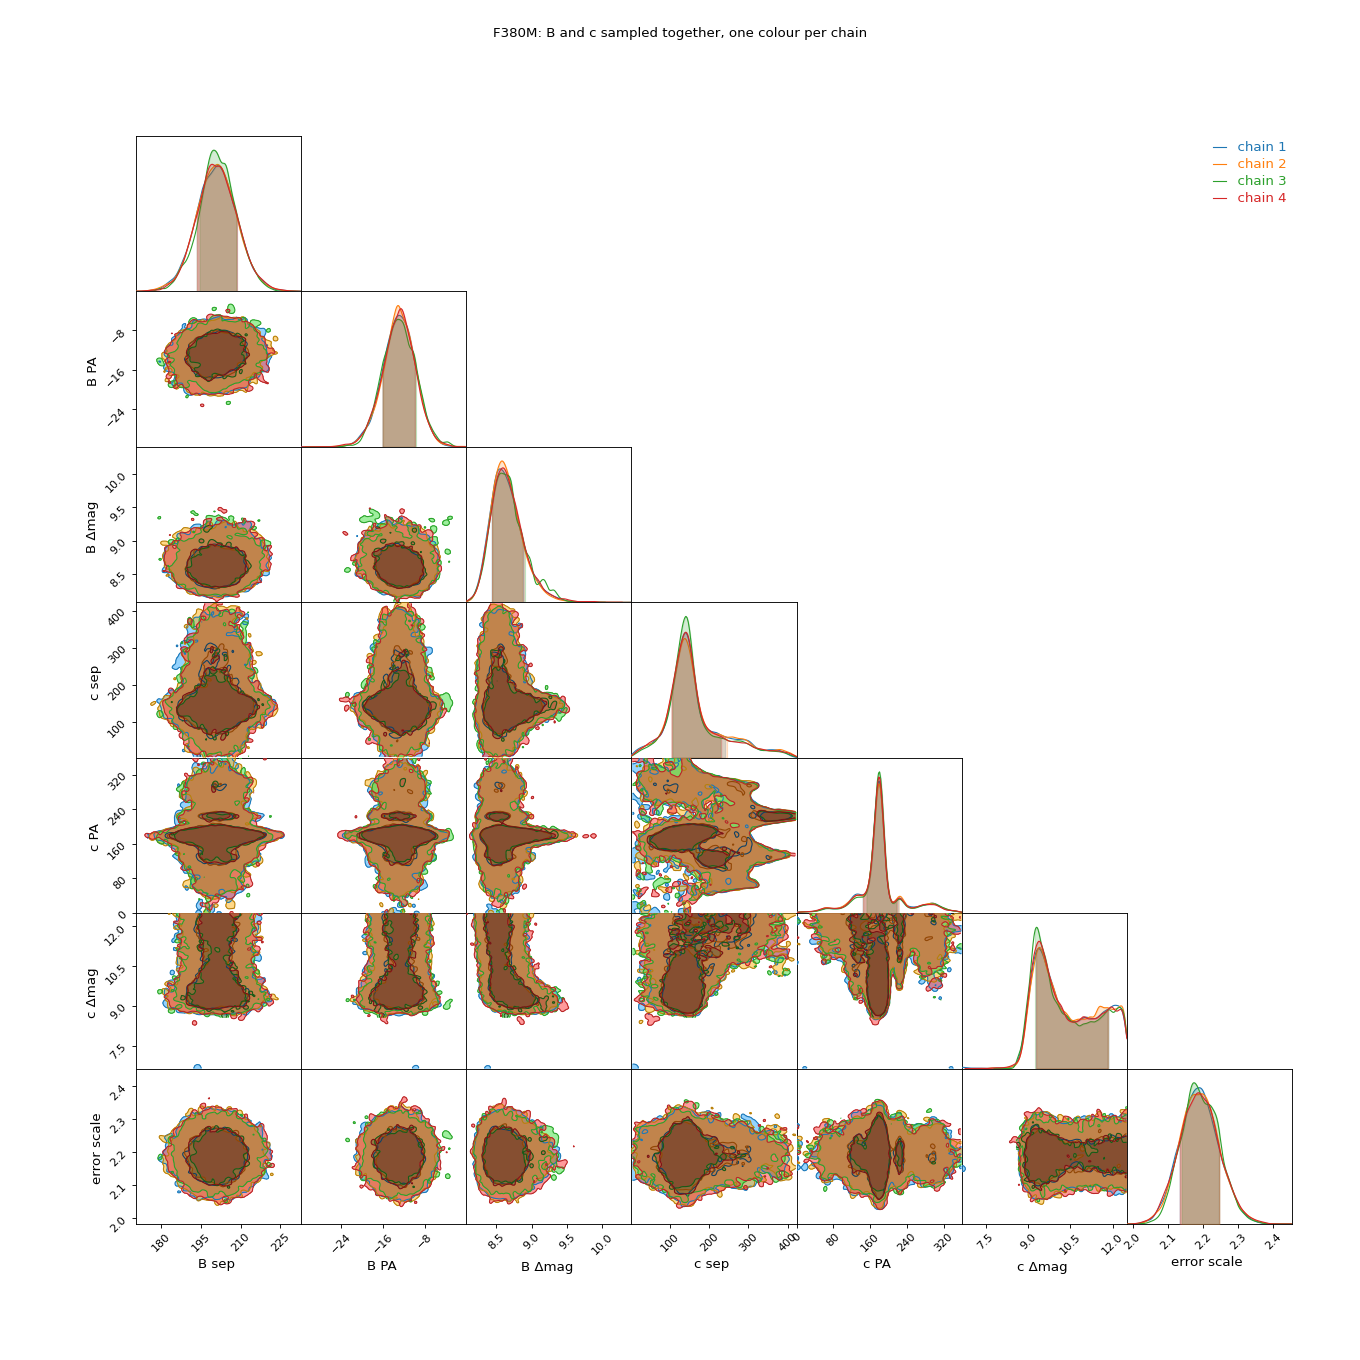

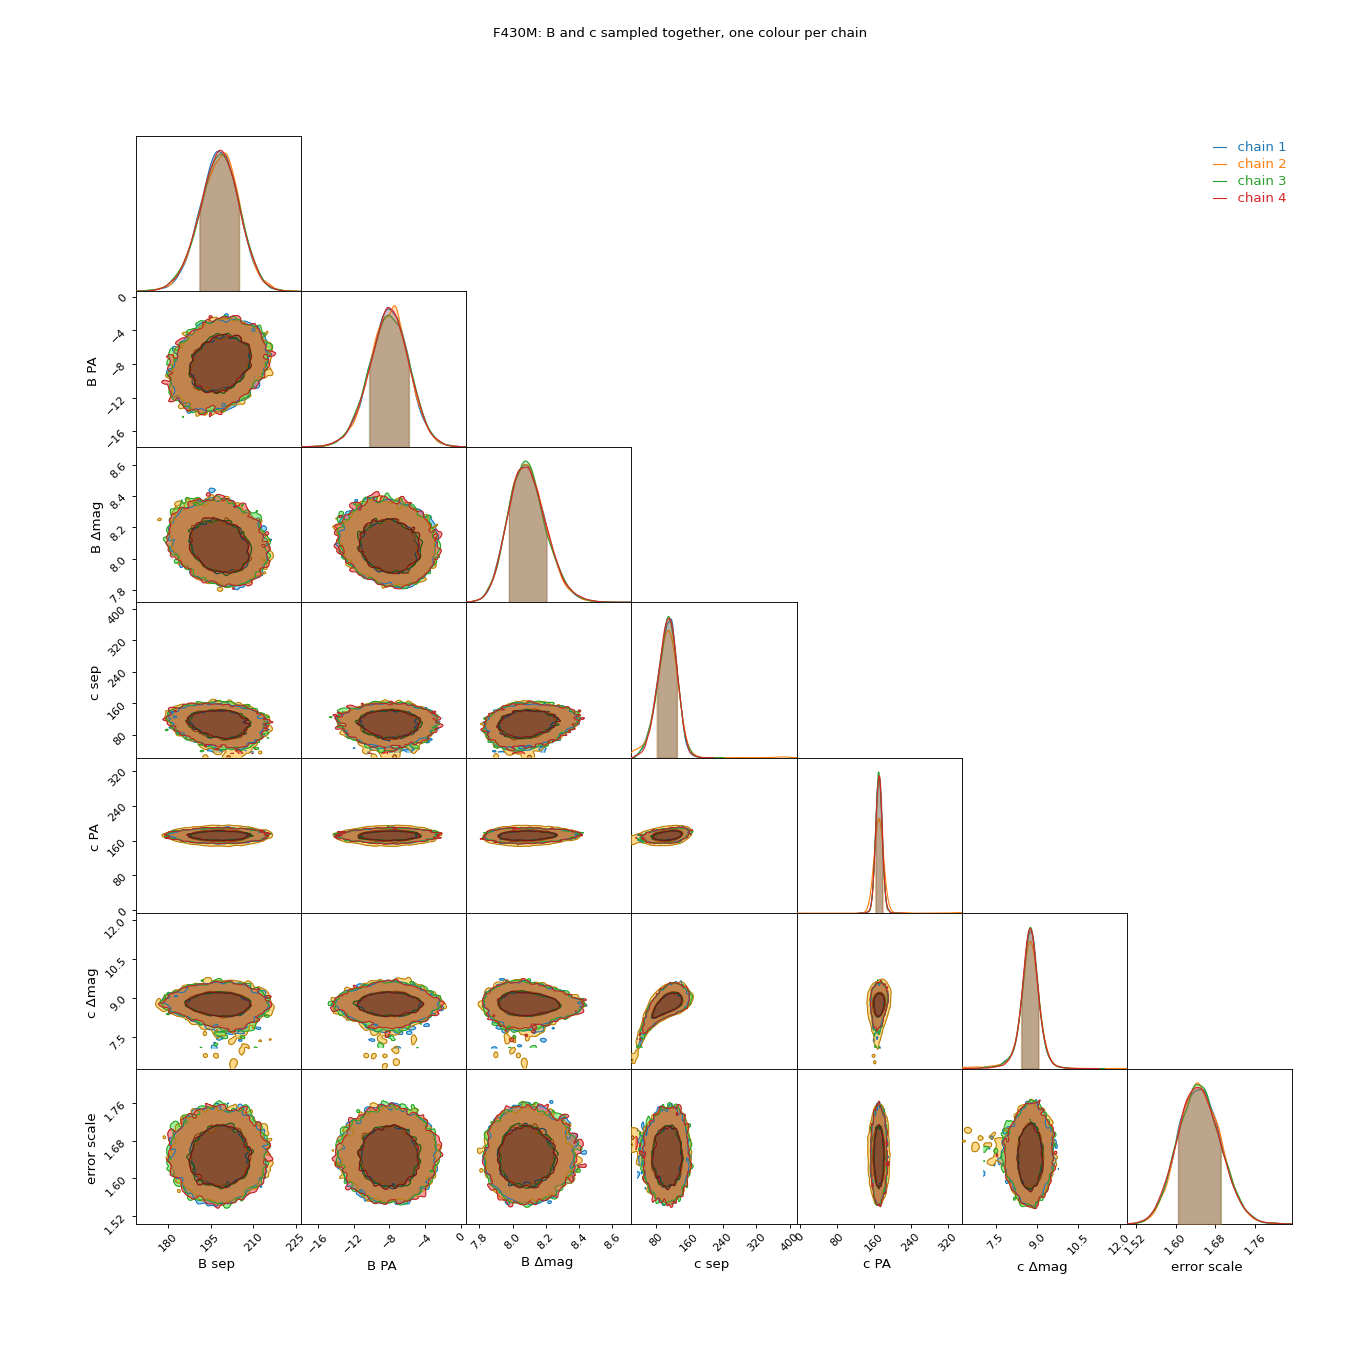

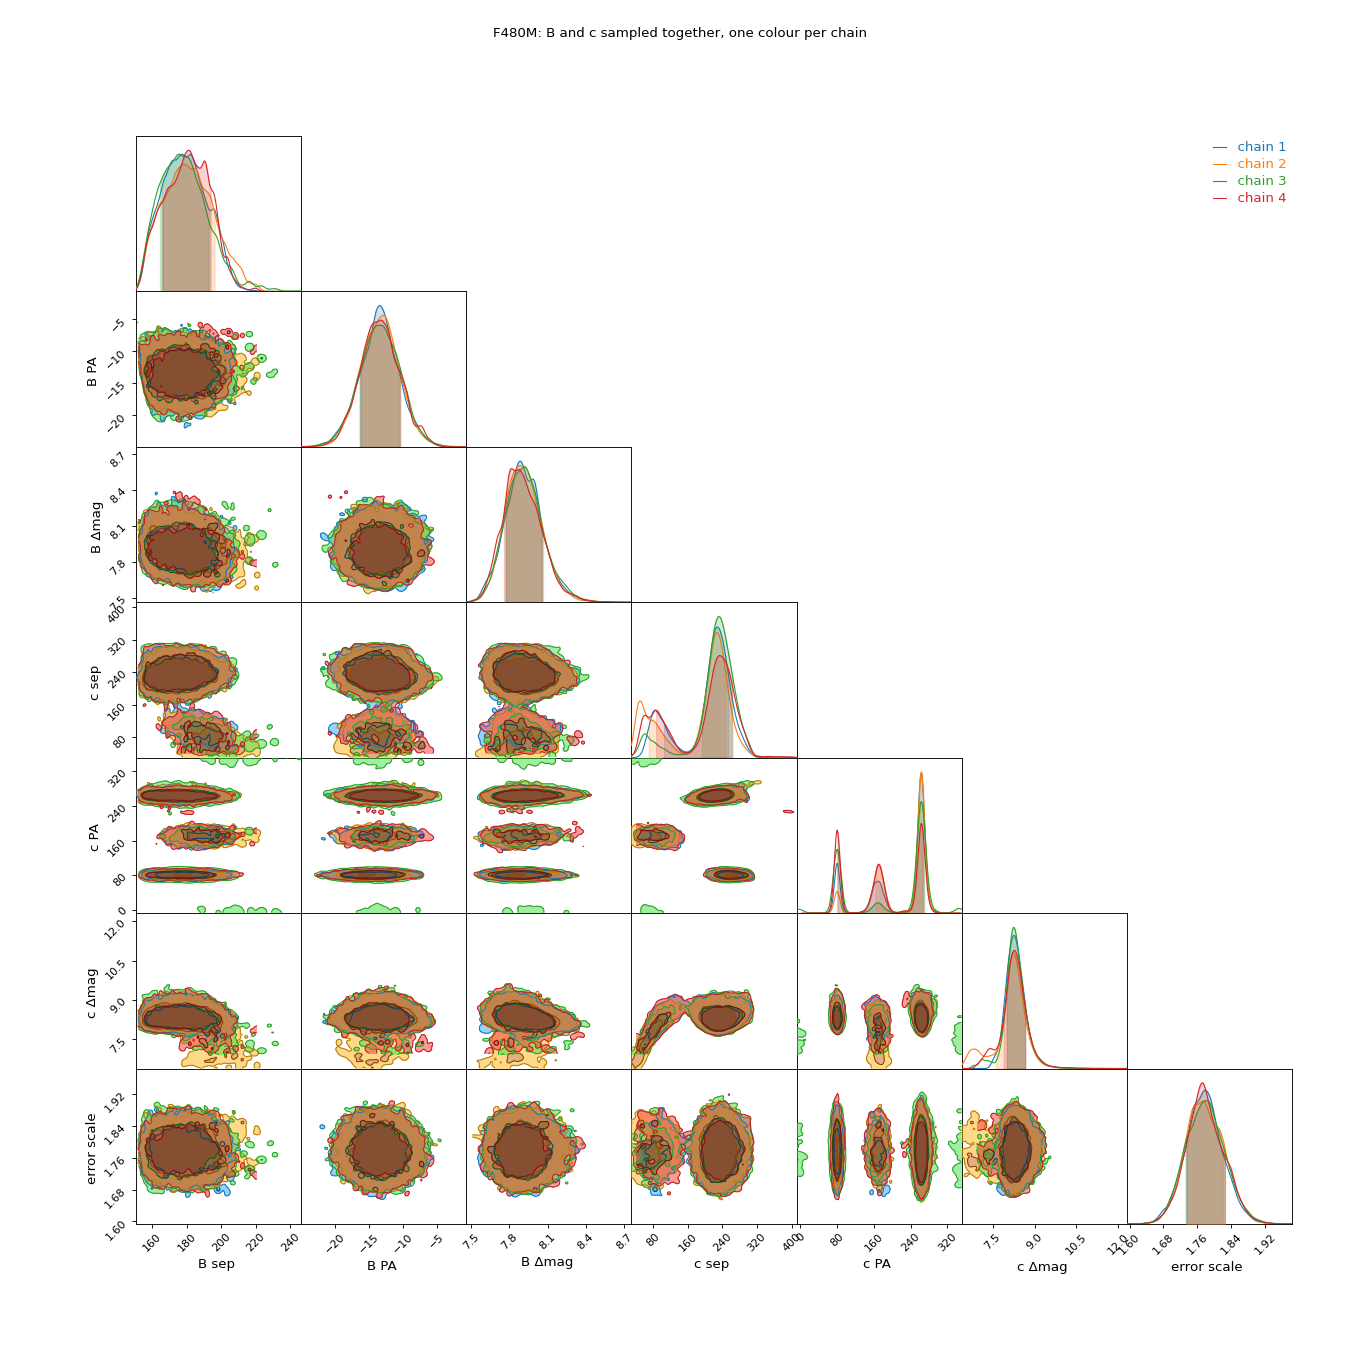

In [22]:
from virgil.plotting import plot_chainconsumer_diagnostics

for filt, chains in posteriors.items():
    _, fig, _ = plot_chainconsumer_diagnostics(
        chains, columns=list(chains["chain 1"].columns)
    )
    fig.suptitle(f"{filt}: B and c sampled together, one colour per chain")
    path = Path(output_path) / "binary" / f"bc_corner_{filt}.png"
    fig.savefig(path, dpi=80)
    plt.close("all")
    display(Image(filename=str(path)))